In [1]:
import sys
sys.path.append("/richmondvol1/rusty/stompy")

In [2]:
%matplotlib widget

In [3]:
import stompy.model.delft.dflow_model as dfm
import numpy as np
import stompy.model.hydro_model as hm
import matplotlib.pyplot as plt
from stompy import utils
from stompy import xr_transect

In [4]:
run_dir='bloom_tracers_v17/run_20220804T1820_20220905T0000_v00'

In [5]:
model = dfm.DFlowModel.load(run_dir)
map_ds = model.map_dataset(chain=False)

INFO:utils:15/16
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells


In [6]:
tidx=-1
if 0: # Sanity check on surface temperature field:
    scal = map_ds['tem1'].isel(time=tidx,laydim=-1).values
    
    fig,ax=plt.subplots(figsize=(9,7))
    ax.set_position([0,0,1,1])
    ax.axis('off')
    ax.set_adjustable('datalim')
    coll = map_ds.grid.plot_cells(ax=ax,values=scal,cmap='turbo',clim=[15,24],lw=0.5,ec='face')
    plt.colorbar(coll,label='Surface temperature (degC)')

In [9]:
# Get a vertical slice along this curve:
if 1:
    line = np.array( [  # Central Bay to San Mateo Bridge
        [552790,4.18799e6],
        [555200,4.1836e6],
        [558900,4.16994e6],
        [561290,4.16467e6],
        [566900,4.15954e6]] )
if 0:
    line = np.array([[553950,4.1722e6],[567820,4.17356e6]]) # west to east, roughly Oakland airport
    
tidx=460

snap_ds = map_ds.isel(time=tidx).compute() # maybe faster to get one time step then slice it.
slice_ds=hm.extract_transect(snap_ds,line,map_ds.grid,include=['tem1','s1','FlowElem_bl'],dx=200)

INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


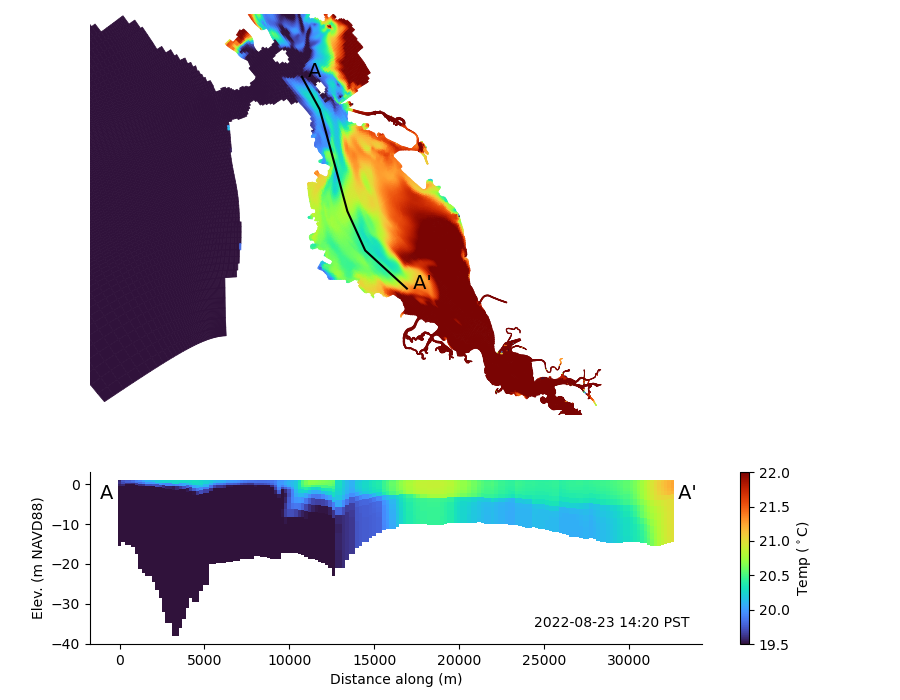

In [10]:
fig,axs = plt.subplots(2,1,figsize=(9,7),height_ratios=[0.7,0.3])

temp_clim=[19.5,22] 

ax=axs[0]
# bathymetry in plan view:
#map_ds.grid.plot_cells(values=map_ds['FlowElem_bl'].values,ax=ax,cmap='terrain',clim=[-25,17],lw=0.5,ec='face')
# temperature in plan view:
map_ds.grid.plot_cells(values=map_ds['tem1'].isel(laydim=-1,time=tidx).values,ax=ax,cmap='turbo',clim=temp_clim,lw=0.5,ec='face')
ax.set_adjustable('datalim')
ax.axis('off')
ax.plot(slice_ds.x_sample,slice_ds.y_sample,'k-')
ax.text(slice_ds.x_sample[0],slice_ds.y_sample[0],' A ',fontsize=14)
ax.text(slice_ds.x_sample[-1],slice_ds.y_sample[-1]," A' ",fontsize=14)
ax.axis((524319, 627117, 4142561, 4196434))
ax=axs[1]
artist = xr_transect.plot_scalar(slice_ds,'tem1',cmap='turbo',ax=ax,clim=temp_clim)
ax.text(0,0,'A ',ha='right',va='top',fontsize=14)
ax.text(slice_ds.d_sample.values[-1],0," A'",ha='left',va='top',fontsize=14)
plt.colorbar(artist,ax=ax,label='Temp ($^\\circ$C)')
ax.set_xlabel('Distance along (m)')
ax.set_ylabel('Elev. (m NAVD88)')
ax.text(0.98,0.1,utils.strftime(snap_ds.time.values - np.timedelta64(8,'h')) +" PST",
        transform=ax.transAxes,ha='right')
ax.spines['top'].set_visible(0) ; ax.spines['right'].set_visible(0)
fig.subplots_adjust(left=0.1,right=0.95,top=0.98,bottom=0.08)

In [187]:
pwd

'/richmondvol1/rusty/wy2022_bloom'

In [ ]:
# Make sure we have a 